In [13]:
import scipy as sp
from scipy.stats import qmc
from numpy.random import Generator, PCG64
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

folder = '../../../Data/'
df_interactions = pd.read_excel(folder+'Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions (GTPR25)')
df_interactions.head()

no_samples = 500
no_edges = len(df_interactions)
seed = 45643564852856852352111
sampler = qmc.LatinHypercube(d = no_edges,rng=Generator(PCG64(seed))) # 17 edges
sample = sampler.random(n=no_samples) # still in a [0,1]^17 hypercube 500 samples!
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM'] # see README.txt
TE_to_ind = {te:i for i,te in enumerate(TEs)}

a = df_interactions['min'].to_numpy()
b = df_interactions['max'].to_numpy()
A = []
for r in range(no_samples):
    weights = a+sample[r,:]*(b-a)
    mat = np.zeros([len(TEs)]*2)
    for index, row in df_interactions.iterrows():
        i = TE_to_ind[row['Source']]
        j = TE_to_ind[row['Target']]
        mat[i,j] = weights[index]
    A.append(mat)
    np.savetxt("../../../Data/Interaction matrices/GTPR2025/A_%s.csv"%r,A[r])

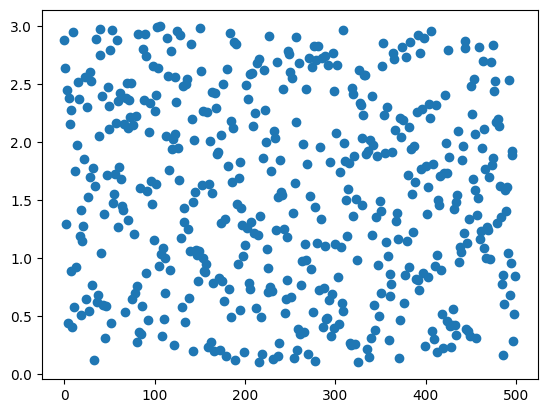

In [16]:
plt.scatter(np.arange(500),[A[r][-2,1] for r in range(500)])